In [2]:
import cv2
from ultralytics import YOLO
import matplotlib.pyplot as plt
import torch
import os

In [3]:
print(torch.cuda.is_available())  # Dovrebbe restituire True
print(torch.cuda.device_count())  # Dovrebbe restituire il numero di GPU disponibili

print(torch.version.cuda)  # Mostra la versione di CUDA utilizzata da PyTorch
print(torch.backends.cudnn.version())  # Mostra la versione di cuDNN

True
1
11.8
90100


In [4]:
# Imposta l'ambiente per evitare il sovraccarico di memoria sulla GPU
os.environ["CUDA_VISIBLE_DEVICES"] = "0"  # Use GPU 0 (set this if you have multiple GPUs)
torch.backends.cudnn.benchmark = True  # Abilita il benchmarking per una migliore efficienza

In [5]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

## YOLO V8 NANO

In [5]:
# Carica un modello YOLO pre-addestrato
model = YOLO(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\yolov8m_olive_trained.pt')

# Addestra il modello con iperparametri ottimizzati
model.train(
    data=r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\olive.yaml', 
    epochs=200,         # Aumenta il numero di epoche
    imgsz=640,         # Aumenta la risoluzione delle immagini
    batch=16,           # Batch size
    lr0=0.01,          # Learning rate ridotto
    patience=10,         # Early stopping per prevenire overfitting
    workers=2
)

model.save('yolov8m_olive_trained.pt')

Ultralytics YOLOv8.2.89  Python-3.10.14 torch-2.4.1+cu118 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
engine\trainer: task=detect, mode=train, model=C:\Users\Bartolo\OlivesDetectionProject\neural_network\yolov8m_olive_trained.pt, data=C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\olive.yaml, epochs=200, time=None, patience=10, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=2, project=None, name=train3, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, re

train: Scanning C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\train\labels.cache... 4665 images, 689 backgrounds, 0 corrupt: 100%|██████████| 4665/4665 [00:00<?, ?it/s]


albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01), CLAHE(p=0.01, clip_limit=(1, 4.0), tile_grid_size=(8, 8))


c:\Users\Bartolo\anaconda3\envs\Olives-detection-project\lib\site-packages\albumentations\check_version.py:49: UserWarning: Error fetching version info <urlopen error [Errno 11001] getaddrinfo failed>
  data = fetch_version_info()
val: Scanning C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\val\labels.cache... 583 images, 92 backgrounds, 0 corrupt: 100%|██████████| 583/583 [00:00<?, ?it/s]


Plotting labels to runs\detect\train3\labels.jpg... 
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: SGD(lr=0.01, momentum=0.9) with parameter groups 77 weight(decay=0.0), 84 weight(decay=0.0005), 83 bias(decay=0.0)
TensorBoard: model graph visualization added 
Image sizes 640 train, 640 val
Using 2 dataloader workers
Logging results to runs\detect\train3
Starting training for 200 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


      1/200      7.78G      1.111     0.5821       1.03        201        640: 100%|██████████| 292/292 [02:09<00:00,  2.26it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 19/19 [00:19<00:00,  1.05s/it]

... (28 outputs left out)

                   all        583       8204      0.891      0.833      0.897      0.602
EarlyStopping: Training stopped early as no improvement observed in last 10 epochs. Best results observed at epoch 1, best model saved as best.pt.
To update EarlyStopping(patience=10) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.



11 epochs completed in 0.462 hours.
Optimizer stripped from runs\detect\train3\weights\last.pt, 52.0MB
Optimizer stripped from runs\detect\train3\weights\best.pt, 52.0MB

Validating runs\detect\train3\weights\best.pt...
Ultralytics YOLOv8.2.89  Python-3.10.14 torch-2.4.1+cu118 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
Model summary (fused): 218 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 19/19 [00:08<00:00,  2.12it/s]


                   all        583       8204      0.911      0.842      0.907      0.623
Speed: 0.2ms preprocess, 8.0ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to runs\detect\train3


In [6]:
model = YOLO(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\runs\detect\train3\weights\best.pt')

# Valutazione del modello addestrato su immagini di validazione
metrics = model.val(data='C:/Users/Bartolo/OLIVEDETECTIONPROJECT/neural_network/data/train_split/olive.yaml')

# Mostra le metriche (precisione, recall, mAP)
print(metrics)

Ultralytics YOLOv8.2.89  Python-3.10.14 torch-2.4.1+cu118 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
Model summary (fused): 218 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs


val: Scanning C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\val\labels.cache... 583 images, 92 backgrounds, 0 corrupt: 100%|██████████| 583/583 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 37/37 [00:13<00:00,  2.81it/s]


                   all        583       8204      0.911      0.842      0.908      0.624
Speed: 0.4ms preprocess, 14.6ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to runs\detect\val
ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x0000021C6D5312D0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.0

## YOLO V8 SMALL

In [6]:
# Carica un modello YOLO pre-addestrato
model = YOLO(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\yolov8s_olive_trained.pt')

# Addestra il modello con iperparametri ottimizzati
model.train(
    data=r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\olive.yaml', 
    epochs=200,         # Aumenta il numero di epoche
    imgsz=640,         # Aumenta la risoluzione delle immagini
    batch=32,           # Batch size
    lr0=0.001,          # Learning rate ridotto
    patience=10,         # Early stopping per prevenire overfitting
    workers=2
)

model.save('yolov8s_olive_trained.pt')

New https://pypi.org/project/ultralytics/8.3.5 available  Update with 'pip install -U ultralytics'
Ultralytics YOLOv8.2.89  Python-3.10.14 torch-2.4.1+cu118 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
engine\trainer: task=detect, mode=train, model=C:\Users\Bartolo\OlivesDetectionProject\neural_network\yolov8s_olive_trained.pt, data=C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\olive.yaml, epochs=200, time=None, patience=10, batch=32, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=2, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_s

100%|██████████| 6.25M/6.25M [00:01<00:00, 4.12MB/s]


AMP: checks passed 


train: Scanning C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\train\labels.cache... 4665 images, 689 backgrounds, 0 corrupt: 100%|██████████| 4665/4665 [00:00<?, ?it/s]


albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01), CLAHE(p=0.01, clip_limit=(1, 4.0), tile_grid_size=(8, 8))


c:\Users\Bartolo\anaconda3\envs\Olives-detection-project\lib\site-packages\albumentations\__init__.py:13: UserWarning: A new version of Albumentations is available: 1.4.17 (you have 1.4.14). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()
val: Scanning C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\val\labels.cache... 583 images, 92 backgrounds, 0 corrupt: 100%|██████████| 583/583 [00:00<?, ?it/s]


... (32 outputs left out)

                   all        583       8204      0.813      0.726      0.798      0.428
EarlyStopping: Training stopped early as no improvement observed in last 10 epochs. Best results observed at epoch 1, best model saved as best.pt.
To update EarlyStopping(patience=10) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.



11 epochs completed in 0.215 hours.
Optimizer stripped from runs\detect\train\weights\last.pt, 6.2MB
Optimizer stripped from runs\detect\train\weights\best.pt, 6.2MB

Validating runs\detect\train\weights\best.pt...
Ultralytics YOLOv8.2.89  Python-3.10.14 torch-2.4.1+cu118 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
Model summary (fused): 168 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 10/10 [00:07<00:00,  1.28it/s]


                   all        583       8204      0.862      0.794      0.867      0.521
Speed: 0.3ms preprocess, 3.4ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to runs\detect\train


In [6]:
# Valutazione del modello addestrato su immagini di validazione
metrics = model.val(data='C:/Users/Bartolo/OLIVEDETECTIONPROJECT/neural_network/data/train_split/olive.yaml')

# Mostra le metriche (precisione, recall, mAP)
print(metrics)

Ultralytics YOLOv8.2.89  Python-3.10.14 torch-2.4.1+cu118 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
Model summary (fused): 168 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs


val: Scanning C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\val\labels.cache... 583 images, 92 backgrounds, 0 corrupt: 100%|██████████| 583/583 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 37/37 [00:13<00:00,  2.71it/s]


                   all        583       8204      0.854        0.8      0.866      0.522
Speed: 0.6ms preprocess, 14.8ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to runs\detect\train62
ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x00000203363A9C30>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,   

## YOLO V8 MEDIUM

In [5]:
# Carica un modello YOLO pre-addestrato
model = YOLO(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\runs\detect\train2\weights\last.pt')

# Addestra il modello con iperparametri ottimizzati
model.train(
    data=r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\olive.yaml', 
    epochs=200,         # Aumenta il numero di epoche
    imgsz=640,         # Aumenta la risoluzione delle immagini
    batch=16,           # Batch size
    lr0=0.001,          # Learning rate ridotto
    patience=10,         # Early stopping per prevenire overfitting
)

model.save(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\yolov8m_olive_trained.pt')

New https://pypi.org/project/ultralytics/8.2.91 available  Update with 'pip install -U ultralytics'
Ultralytics YOLOv8.2.89  Python-3.10.14 torch-2.4.1+cu118 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
engine\trainer: task=detect, mode=train, model=yolov8m.pt, data=C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\olive.yaml, epochs=200, time=None, patience=10, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train2, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnos

train: Scanning C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\train\labels.cache... 4665 images, 689 backgrounds, 0 corrupt: 100%|██████████| 4665/4665 [00:00<?, ?it/s]


albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01), CLAHE(p=0.01, clip_limit=(1, 4.0), tile_grid_size=(8, 8))


val: Scanning C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\val\labels.cache... 583 images, 92 backgrounds, 0 corrupt: 100%|██████████| 583/583 [00:00<?, ?it/s]


Plotting labels to runs\detect\train2\labels.jpg... 
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.001' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: SGD(lr=0.01, momentum=0.9) with parameter groups 77 weight(decay=0.0), 84 weight(decay=0.0005), 83 bias(decay=0.0)
TensorBoard: model graph visualization added 
Image sizes 640 train, 640 val
Using 8 dataloader workers
Logging results to runs\detect\train2
Starting training for 200 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


      1/200      2.06G      2.035      1.631      1.558        200        640: 100%|██████████| 292/292 [02:18<00:00,  2.11it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 19/19 [00:10<00:00,  1.76it/s]

... (152 outputs left out)

     54/200      7.48G      1.175     0.6254      1.061        108        640: 100%|██████████| 292/292 [02:00<00:00,  2.43it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 19/19 [01:16<00:00,  4.03s/it]

                   all        583       8204      0.897      0.846      0.904      0.613



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


     55/200      7.23G      1.154     0.6133      1.047        301        640:  59%|█████▊    | 171/292 [02:34<01:49,  1.10it/s]

In [6]:
# Carica un modello YOLO pre-addestrato
model = YOLO(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\runs\detect\train2\weights\last.pt')

# Addestra il modello con iperparametri ottimizzati
model.train(
    data=r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\olive.yaml', 
    epochs=200,         # Aumenta il numero di epoche
    imgsz=640,         # Aumenta la risoluzione delle immagini
    batch=16,           # Batch size
    lr0=0.001,          # Learning rate ridotto
    patience=10,         # Early stopping per prevenire overfitting
)

model.save(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\yolov8m_olive_trained.pt')

Ultralytics YOLOv8.2.89  Python-3.10.14 torch-2.4.1+cu118 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
engine\trainer: task=detect, mode=train, model=C:\Users\Bartolo\OlivesDetectionProject\neural_network\runs\detect\train2\weights\last.pt, data=C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\olive.yaml, epochs=200, time=None, patience=10, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train3, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classe

train: Scanning C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\train\labels.cache... 4665 images, 689 backgrounds, 0 corrupt: 100%|██████████| 4665/4665 [00:00<?, ?it/s]


albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01), CLAHE(p=0.01, clip_limit=(1, 4.0), tile_grid_size=(8, 8))


c:\Users\Bartolo\anaconda3\envs\Olives-detection-project\lib\site-packages\albumentations\check_version.py:49: UserWarning: Error fetching version info <urlopen error [Errno 11001] getaddrinfo failed>
  data = fetch_version_info()
val: Scanning C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\val\labels.cache... 583 images, 92 backgrounds, 0 corrupt: 100%|██████████| 583/583 [00:00<?, ?it/s]


Plotting labels to runs\detect\train3\labels.jpg... 
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.001' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: SGD(lr=0.01, momentum=0.9) with parameter groups 77 weight(decay=0.0), 84 weight(decay=0.0005), 83 bias(decay=0.0)
TensorBoard: model graph visualization added 
Image sizes 640 train, 640 val
Using 8 dataloader workers
Logging results to runs\detect\train3
Starting training for 200 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


      1/200      2.18G      1.105     0.5766      1.029        200        640: 100%|██████████| 292/292 [02:11<00:00,  2.22it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 19/19 [00:10<00:00,  1.80it/s]

... (30 outputs left out)

                   all        583       8204      0.909      0.831      0.903      0.608
EarlyStopping: Training stopped early as no improvement observed in last 10 epochs. Best results observed at epoch 1, best model saved as best.pt.
To update EarlyStopping(patience=10) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.



11 epochs completed in 0.422 hours.
Optimizer stripped from runs\detect\train3\weights\last.pt, 52.0MB
Optimizer stripped from runs\detect\train3\weights\best.pt, 52.0MB

Validating runs\detect\train3\weights\best.pt...
Ultralytics YOLOv8.2.89  Python-3.10.14 torch-2.4.1+cu118 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
Model summary (fused): 218 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 19/19 [00:20<00:00,  1.07s/it]


                   all        583       8204      0.903      0.853       0.91      0.627
Speed: 0.4ms preprocess, 27.3ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to runs\detect\train3


In [7]:
# Valutazione del modello addestrato su immagini di validazione
metrics = model.val(data='C:/Users/Bartolo/OLIVEDETECTIONPROJECT/neural_network/data/train_split/olive.yaml')

# Mostra le metriche (precisione, recall, mAP)
print(metrics)

Ultralytics YOLOv8.2.89  Python-3.10.14 torch-2.4.1+cu118 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
Model summary (fused): 218 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs


val: Scanning C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\val\labels.cache... 583 images, 92 backgrounds, 0 corrupt: 100%|██████████| 583/583 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 37/37 [00:17<00:00,  2.12it/s]


                   all        583       8204      0.904      0.853       0.91      0.628
Speed: 0.4ms preprocess, 23.0ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to runs\detect\train32
ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x000002073926BC40>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,   

In [7]:
model = YOLO(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\yolov8m_olive_trained.pt')

# Valutazione del modello addestrato su immagini di validazione
metrics = model.val(data='C:/Users/Bartolo/OLIVEDETECTIONPROJECT/neural_network/data/train_split/olive.yaml')

# Mostra le metriche (precisione, recall, mAP)
print(metrics)

Ultralytics YOLOv8.2.89  Python-3.10.14 torch-2.4.1+cu118 CPU (Intel Core(TM) i9-14900HX)
Model summary (fused): 218 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs


val: Scanning C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\train_split\val\labels.cache... 583 images, 92 backgrounds, 0 corrupt: 100%|██████████| 583/583 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95):  30%|██▉       | 11/37 [00:54<02:09,  4.97s/it]


KeyboardInterrupt: 

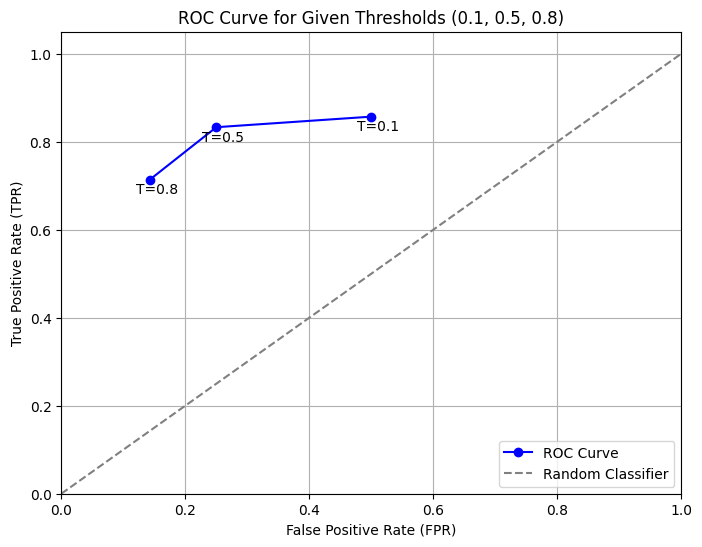

In [1]:
import matplotlib.pyplot as plt

# Dati TPR e FPR per le varie soglie
fpr_values = [0.5, 0.25, 0.143]
tpr_values = [0.857, 0.833, 0.714]
thresholds = [0.1, 0.5, 0.8]

# Plot della curva ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr_values, tpr_values, marker='o', color='b', label='ROC Curve')

# Aggiunta delle etichette per le soglie
for i, threshold in enumerate(thresholds):
    plt.annotate(f'T={threshold}', (fpr_values[i], tpr_values[i]), textcoords="offset points", xytext=(5,-10), ha='center')

# Linea della classificazione casuale
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Classifier')

# Impostazioni del grafico
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve for Given Thresholds (0.1, 0.5, 0.8)')
plt.legend(loc="lower right")
plt.grid()
plt.show()
